In [1]:
# Install library pendukung
!pip install scikit-image pillow rembg onnxruntime opencv-python
!pip install -q ultralytics

In [2]:
import os
import cv2
import shutil
import random
import numpy as np
from pathlib import Path
from tqdm import tqdm
from PIL import Image

from rembg import remove, new_session

from ultralytics import YOLO

from sklearn.model_selection import train_test_split

Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
# Dataset asli (hanya memiliki folder train)
source_dir = "/content/drive/MyDrive/RISET/Dataset Sapi/Data"

# Dataset baru hasil pembagian
output_removebg = "/content/drive/MyDrive/RISET/Dataset_NoBackground"

SUPPORTED_FORMATS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff"
}

In [5]:
def remove_background_dataset(
    input_dir: str,
    output_dir: str,
    model_name: str = "u2net",
    keep_subfolder_structure: bool = True
):

    input_path = Path(input_dir)
    output_path = Path(output_dir)

    if not input_path.exists():
        raise FileNotFoundError(f"Folder tidak ditemukan : {input_dir}")

    output_path.mkdir(parents=True, exist_ok=True)

    # Ambil semua gambar
    all_images = [
        f for f in input_path.rglob("*")
        if f.suffix.lower() in SUPPORTED_FORMATS
    ]

    if len(all_images) == 0:
        print("Tidak ada gambar ditemukan.")
        return

    print("="*60)
    print("REMOVE BACKGROUND MENGGUNAKAN U²-NET")
    print("="*60)
    print(f"Input Folder  : {input_dir}")
    print(f"Output Folder : {output_dir}")
    print(f"Model         : {model_name}")
    print(f"Total Gambar  : {len(all_images)}")
    print("="*60)

    # Load model sekali saja
    session = new_session(model_name)

    success = 0
    skipped = 0
    failed = 0

    for img_path in tqdm(all_images, desc="Processing", unit="image"):

        try:

            # Menentukan lokasi output
            if keep_subfolder_structure:

                relative = img_path.relative_to(input_path)

                save_path = (
                    output_path /
                    relative.parent /
                    (img_path.stem + ".png")
                )

            else:

                save_path = output_path / (img_path.stem + ".png")

            # Skip jika sudah ada
            if save_path.exists():

                skipped += 1
                continue

            save_path.parent.mkdir(
                parents=True,
                exist_ok=True
            )

            # Buka gambar
            with Image.open(img_path) as img:

                img = img.convert("RGBA")

                # Remove Background
                result = remove(
                    img,
                    session=session
                )

                # Simpan PNG
                result.save(
                    save_path,
                    format="PNG"
                )

            success += 1

        except Exception as e:

            failed += 1
            tqdm.write(
                f"Gagal : {img_path.name}\n{e}"
            )

    print("\n")
    print("SELESAI")
    print(f"Berhasil : {success}")
    print(f"Dilewati : {skipped}")
    print(f"Gagal    : {failed}")

In [6]:
# remove_background_dataset(
#     input_dir=source_dir,
#     output_dir=output_removebg,
#     model_name="u2net",
#     keep_subfolder_structure=True
# )

In [7]:
import os
import cv2
import numpy as np
from pathlib import Path
from tqdm import tqdm

# Folder hasil remove background (PNG dengan alpha channel)
mask_dir = "/content/drive/MyDrive/RISET/Dataset_NoBackground"

# Folder output label cow
label_output = "/content/drive/MyDrive/RISET/Dataset Sapi/Data/labels/Cow_Label"

os.makedirs(label_output, exist_ok=True)

image_files = []

for ext in ["*.png","*.jpg","*.jpeg"]:
    image_files.extend(Path(mask_dir).rglob(ext))

print(f"Total gambar : {len(image_files)}")

for img_path in tqdm(image_files):

    # Membaca PNG RGBA
    rgba = cv2.imread(str(img_path), cv2.IMREAD_UNCHANGED)

    if rgba is None:
        continue

    # Pastikan mempunyai alpha channel
    if rgba.shape[2] != 4:
        continue

    # Alpha channel menjadi mask
    alpha = rgba[:, :, 3]

    _, mask = cv2.threshold(alpha, 1, 255, cv2.THRESH_BINARY)

    # Cari contour terbesar (diasumsikan sapi)
    contours, _ = cv2.findContours(
        mask,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    if len(contours) == 0:
        continue

    contour = max(contours, key=cv2.contourArea)

    x, y, w, h = cv2.boundingRect(contour)

    H, W = mask.shape

    # Konversi ke format YOLO
    x_center = (x + w / 2) / W
    y_center = (y + h / 2) / H
    width = w / W
    height = h / H

    # class 0 = cow
    yolo_label = f"1 {x_center:.6f} {y_center:.6f} {width:.6f} {height:.6f}"

    txt_name = img_path.stem + ".txt"

    with open(os.path.join(label_output, txt_name), "w") as f:
        f.write(yolo_label)

print("Selesai membuat label cow.")

Total gambar : 228


100%|██████████| 228/228 [01:01<00:00,  3.74it/s]

Selesai membuat label cow.


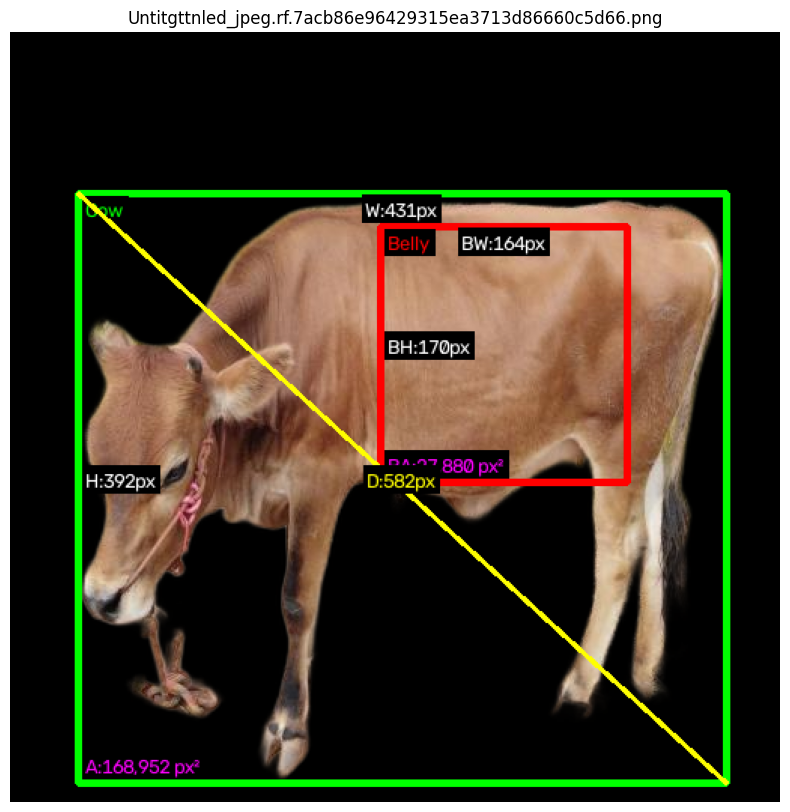

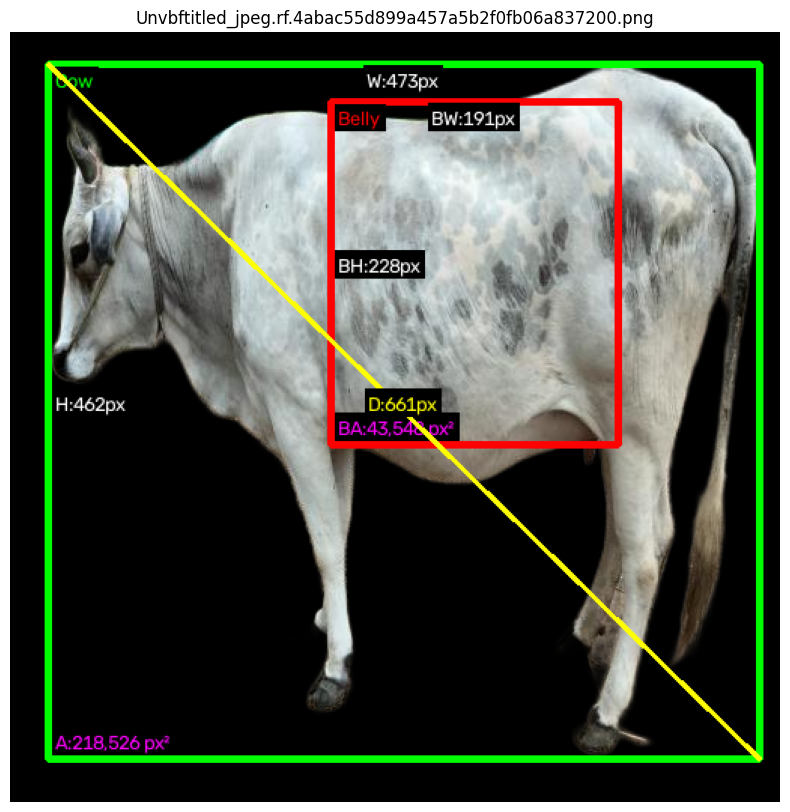

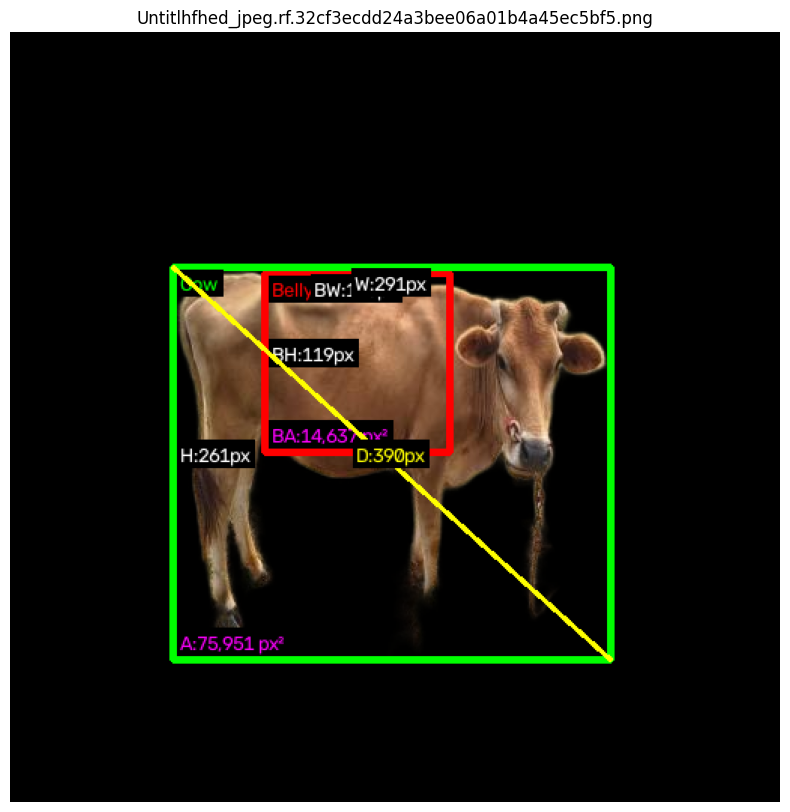

In [8]:
import os
import cv2
import random
import numpy as np
import matplotlib.pyplot as plt

# =====================================================
# PATH
# =====================================================
image_dir = "/content/drive/MyDrive/RISET/Dataset_NoBackground/images"

cow_label_dir = "/content/drive/MyDrive/RISET/Dataset Sapi/Data/labels/Cow_Label"
belly_label_dir = "/content/drive/MyDrive/RISET/Dataset Sapi/Data/labels/Belly_Label"

# =====================================================
# AMBIL 3 GAMBAR ACAK
# =====================================================
image_files = [
    f for f in os.listdir(image_dir)
    if f.lower().endswith((".jpg",".jpeg",".png"))
]

image_files = random.sample(image_files, min(3, len(image_files)))

# =====================================================
# LOOP
# =====================================================
for image_name in image_files:

    image_path = os.path.join(image_dir, image_name)

    img = cv2.imread(image_path)

    if img is None:
        continue

    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    H, W = img.shape[:2]

    # =====================================================
    # FUNGSI GAMBAR
    # =====================================================
    def draw_measurement(label_path, class_name, color):

        if not os.path.exists(label_path):
            return

        with open(label_path) as f:
            lines = f.readlines()

        for line in lines:

            cls, xc, yc, bw, bh = map(float, line.split())

            xc *= W
            yc *= H
            bw *= W
            bh *= H

            x1 = int(xc - bw/2)
            y1 = int(yc - bh/2)

            x2 = int(xc + bw/2)
            y2 = int(yc + bh/2)

            # --------------------------
            # Bounding Box
            # --------------------------
            cv2.rectangle(img,(x1,y1),(x2,y2),color,3)

            # --------------------------
            # Perhitungan
            # --------------------------
            length = x2 - x1
            width = y2 - y1
            diagonal = int(np.sqrt(length**2 + width**2))
            area = length * width

            font = cv2.FONT_HERSHEY_SIMPLEX
            font_scale = 0.45
            thickness = 1

            # --------------------------
            # Bounding Box
            # --------------------------
            cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)

            # =====================================================
            # Fungsi tulisan dengan background
            # =====================================================
            def draw_text(text, x, y, txt_color=(255,255,255)):

                (tw, th), _ = cv2.getTextSize(
                    text,
                    font,
                    font_scale,
                    thickness
                )

                cv2.rectangle(
                    img,
                    (x-2, y-th-3),
                    (x+tw+2, y+3),
                    (0,0,0),
                    -1
                )

                cv2.putText(
                    img,
                    text,
                    (x,y),
                    font,
                    font_scale,
                    txt_color,
                    thickness,
                    cv2.LINE_AA
                )

            # --------------------------
            # Nama objek (dalam box)
            # --------------------------
            draw_text(
                class_name,
                x1 + 5,
                y1 + 16,
                color
            )

            # --------------------------
            # Garis Horizontal
            # --------------------------
            cv2.line(
                img,
                (x1, y1),
                (x2, y1),
                color,
                2
            )

            # --------------------------
            # Garis Vertikal
            # --------------------------
            cv2.line(
                img,
                (x1, y1),
                (x1, y2),
                color,
                2
            )

            # --------------------------
            # Width di tengah garis horizontal
            # --------------------------
            if class_name == "Cow":
                txt = f"W:{length}px"
            else:
                txt = f"BW:{length}px"

            (tw, th), _ = cv2.getTextSize(
                txt,
                font,
                font_scale,
                thickness
            )

            draw_text(
                txt,
                int((x1+x2)/2 - tw/2),
                y1 + 16,
                (255,255,255)
            )

            # --------------------------
            # Height di tengah garis vertikal
            # --------------------------
            if class_name == "Cow":
                txt = f"H:{width}px"
            else:
                txt = f"BH:{width}px"

            draw_text(
                txt,
                x1 + 5,
                int((y1+y2)/2),
                (255,255,255)
            )

            # --------------------------
            # Diagonal
            # --------------------------
            if class_name == "Cow":

                cv2.line(
                    img,
                    (x1,y1),
                    (x2,y2),
                    (255,255,0),
                    2
                )

                txt = f"D:{diagonal}px"

                (tw, th), _ = cv2.getTextSize(
                    txt,
                    font,
                    font_scale,
                    thickness
                )

                draw_text(
                    txt,
                    int((x1+x2)/2 - tw/2),
                    int((y1+y2)/2),
                    (255,255,0)
                )

            # --------------------------
            # Area pojok kiri bawah
            # --------------------------
            if class_name == "Cow":
                txt = f"A:{area:,} px²"
            else:
                txt = f"BA:{area:,} px²"

            draw_text(
                txt,
                x1 + 5,
                y2 - 6,
                (255,0,255)
            )

    # =====================================================
    # BELLY
    # =====================================================
    belly_txt = os.path.join(
        belly_label_dir,
        os.path.splitext(image_name)[0]+".txt"
    )

    draw_measurement(
        belly_txt,
        "Belly",
        (255,0,0)
    )

    # =====================================================
    # COW
    # =====================================================
    cow_txt = os.path.join(
        cow_label_dir,
        os.path.splitext(image_name)[0]+".txt"
    )

    draw_measurement(
        cow_txt,
        "Cow",
        (0,255,0)
    )

    # =====================================================
    # SHOW
    # =====================================================
    plt.figure(figsize=(10,10))
    plt.imshow(img)
    plt.title(image_name)
    plt.axis("off")
    plt.show()

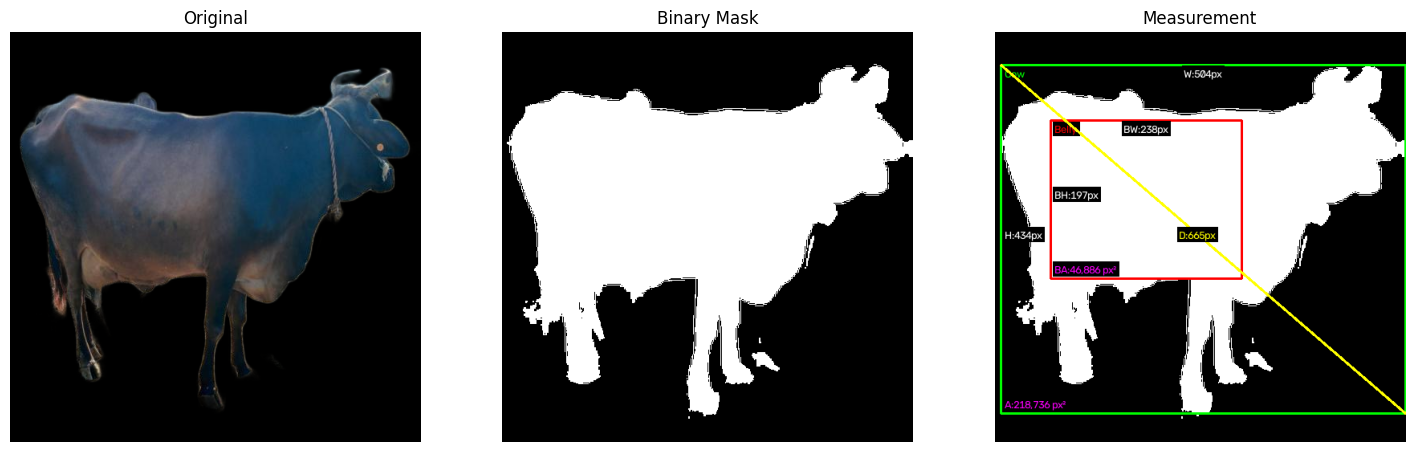

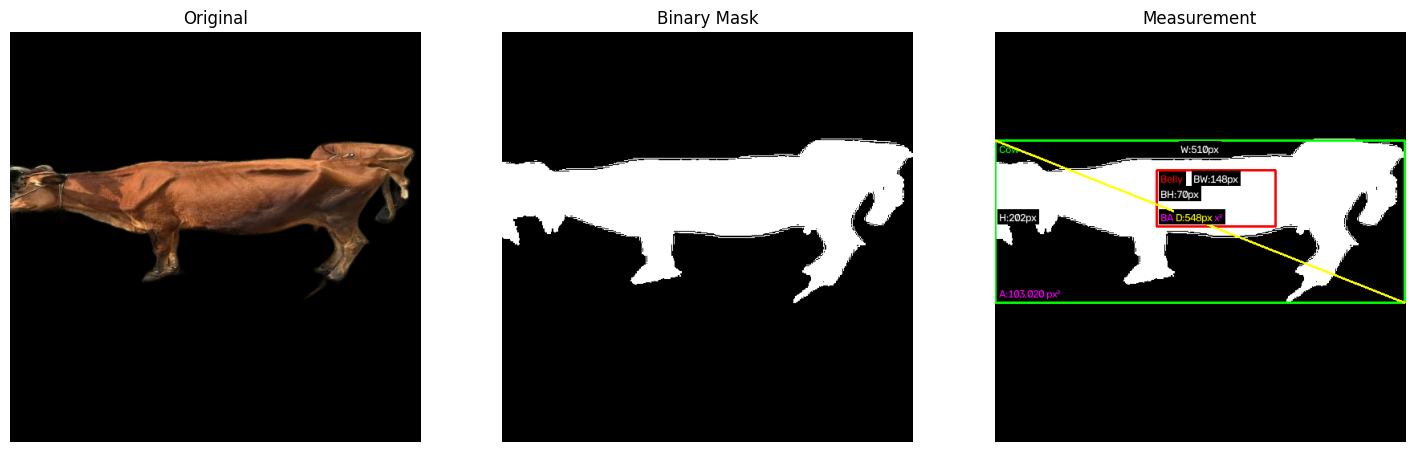

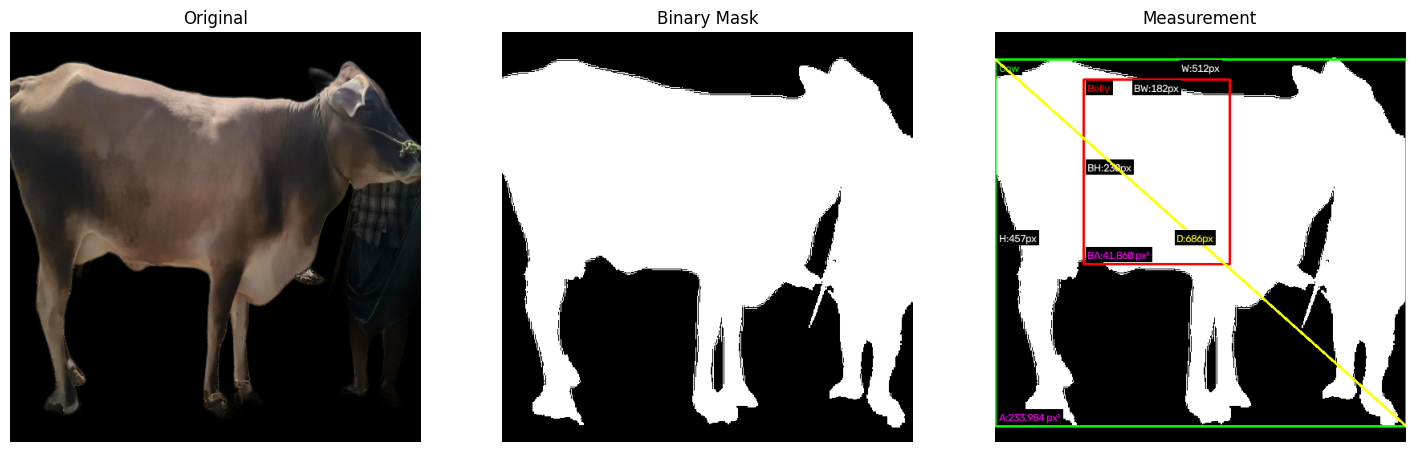

In [9]:
import os
import cv2
import random
import numpy as np
import matplotlib.pyplot as plt


# =====================================================
# PATH
# =====================================================
image_dir = "/content/drive/MyDrive/RISET/Dataset_NoBackground/images"

cow_label_dir = "/content/drive/MyDrive/RISET/Dataset Sapi/Data/labels/Cow_Label"
belly_label_dir = "/content/drive/MyDrive/RISET/Dataset Sapi/Data/labels/Belly_Label"


# =====================================================
# AMBIL 3 GAMBAR ACAK
# =====================================================
image_files = [
    f for f in os.listdir(image_dir)
    if f.lower().endswith((".jpg",".jpeg",".png"))
]

image_files = random.sample(
    image_files,
    min(3, len(image_files))
)


# =====================================================
# LOOP
# =====================================================
for image_name in image_files:

    image_path = os.path.join(
        image_dir,
        image_name
    )


    # =====================================================
    # LOAD MASK
    # =====================================================
    mask_img = cv2.imread(
        image_path,
        cv2.IMREAD_UNCHANGED
    )


    if mask_img is None:
        continue


    # cek alpha
    if mask_img.shape[2] != 4:
        print("Tidak ada alpha:", image_name)
        continue


    alpha = mask_img[:,:,3]


    # objek putih background hitam
    mask = np.zeros_like(alpha)
    mask[alpha > 0] = 255



    # ubah ke RGB agar bisa diberi anotasi
    img = cv2.cvtColor(
        mask,
        cv2.COLOR_GRAY2RGB
    )


    H, W = mask.shape[:2]



    # =====================================================
    # FUNGSI DRAW
    # =====================================================
    def draw_measurement(label_path, class_name, color):

        if not os.path.exists(label_path):
            return


        with open(label_path) as f:
            lines = f.readlines()



        for line in lines:


            cls, xc, yc, bw, bh = map(
                float,
                line.split()
            )


            # YOLO koordinat
            xc *= W
            yc *= H
            bw *= W
            bh *= H


            x1 = int(xc - bw/2)
            y1 = int(yc - bh/2)

            x2 = int(xc + bw/2)
            y2 = int(yc + bh/2)



            # ukuran
            length = x2-x1
            width = y2-y1


            diagonal = int(
                np.sqrt(
                    length**2 + width**2
                )
            )


            area = length*width



            font = cv2.FONT_HERSHEY_SIMPLEX
            font_scale = 0.45
            thickness = 1



            # =========================================
            # BOX
            # =========================================
            cv2.rectangle(
                img,
                (x1,y1),
                (x2,y2),
                color,
                2
            )



            # =========================================
            # TEXT DENGAN BACKGROUND
            # =========================================
            def draw_text(
                text,
                x,
                y,
                txt_color=(255,255,255)
            ):


                (tw,th),_=cv2.getTextSize(
                    text,
                    font,
                    font_scale,
                    thickness
                )


                cv2.rectangle(
                    img,
                    (x-2,y-th-3),
                    (x+tw+2,y+3),
                    (0,0,0),
                    -1
                )


                cv2.putText(
                    img,
                    text,
                    (x,y),
                    font,
                    font_scale,
                    txt_color,
                    thickness,
                    cv2.LINE_AA
                )



            # =========================================
            # NAMA OBJEK
            # =========================================
            draw_text(
                class_name,
                x1+5,
                y1+16,
                color
            )



            # =========================================
            # GARIS WIDTH
            # =========================================
            cv2.line(
                img,
                (x1,y1),
                (x2,y1),
                color,
                2
            )


            if class_name == "Cow":
                txt = f"W:{length}px"
            else:
                txt = f"BW:{length}px"



            (tw,th),_=cv2.getTextSize(
                txt,
                font,
                font_scale,
                thickness
            )


            draw_text(
                txt,
                int((x1+x2)/2-tw/2),
                y1+16
            )



            # =========================================
            # GARIS HEIGHT
            # =========================================
            cv2.line(
                img,
                (x1,y1),
                (x1,y2),
                color,
                2
            )



            if class_name=="Cow":
                txt=f"H:{width}px"
            else:
                txt=f"BH:{width}px"



            draw_text(
                txt,
                x1+5,
                int((y1+y2)/2)
            )



            # =========================================
            # DIAGONAL COW
            # =========================================
            if class_name=="Cow":


                cv2.line(
                    img,
                    (x1,y1),
                    (x2,y2),
                    (255,255,0),
                    2
                )


                txt=f"D:{diagonal}px"


                draw_text(
                    txt,
                    int((x1+x2)/2-30),
                    int((y1+y2)/2),
                    (255,255,0)
                )



            # =========================================
            # AREA
            # =========================================
            if class_name=="Cow":
                txt=f"A:{area:,} px²"
            else:
                txt=f"BA:{area:,} px²"



            draw_text(
                txt,
                x1+5,
                y2-6,
                (255,0,255)
            )




    # =====================================================
    # LABEL BELLY
    # =====================================================
    belly_txt = os.path.join(
        belly_label_dir,
        os.path.splitext(image_name)[0]+".txt"
    )


    draw_measurement(
        belly_txt,
        "Belly",
        (255,0,0)
    )



    # =====================================================
    # LABEL COW
    # =====================================================
    cow_txt = os.path.join(
        cow_label_dir,
        os.path.splitext(image_name)[0]+".txt"
    )


    draw_measurement(
        cow_txt,
        "Cow",
        (0,255,0)
    )



    # =====================================================
    # DISPLAY
    # =====================================================
    plt.figure(figsize=(18,6))

    plt.subplot(1,3,1)
    plt.imshow(cv2.cvtColor(cv2.imread(image_path), cv2.COLOR_BGR2RGB))
    plt.title("Original")
    plt.axis("off")


    plt.subplot(1,3,2)
    plt.imshow(mask, cmap="gray")
    plt.title("Binary Mask")
    plt.axis("off")


    plt.subplot(1,3,3)
    plt.imshow(img)
    plt.title("Measurement")
    plt.axis("off")

    plt.show()

In [10]:
import os

# =====================================================
# PATH
# =====================================================
cow_dir = "/content/drive/MyDrive/RISET/Dataset Sapi/Data/labels/Cow_Label"
belly_dir = "/content/drive/MyDrive/RISET/Dataset Sapi/Data/labels/Belly_Label"

output_dir = "/content/drive/MyDrive/RISET/Dataset Sapi/Data/labels/YOLO_Labels"

os.makedirs(output_dir, exist_ok=True)

# =====================================================
# AMBIL SEMUA NAMA FILE
# =====================================================
files = set()

files.update(os.listdir(cow_dir))
files.update(os.listdir(belly_dir))

# =====================================================
# GABUNGKAN
# =====================================================
for file in sorted(files):

    lines = []

    cow_path = os.path.join(cow_dir, file)

    if os.path.exists(cow_path):

        with open(cow_path) as f:

            for line in f:

                data = line.strip().split()

                if len(data) == 5:

                    # class Cow = 1
                    data[0] = "1"

                    lines.append(" ".join(data))


    belly_path = os.path.join(belly_dir, file)

    if os.path.exists(belly_path):

        with open(belly_path) as f:

            for line in f:

                data = line.strip().split()

                if len(data) == 5:

                    # class Belly = 0
                    data[0] = "0"

                    lines.append(" ".join(data))


    with open(os.path.join(output_dir, file), "w") as f:

        f.write("\n".join(lines))

print("Semua label berhasil digabung.")

Semua label berhasil digabung.


In [11]:
# import os
# import shutil
# from sklearn.model_selection import train_test_split

# # =====================================================
# # PATH
# # =====================================================
# image_dir = "/content/drive/MyDrive/RISET/Dataset_NoBackground/images"

# label_dir = "/content/drive/MyDrive/RISET/Dataset Sapi/Data/labels/YOLO_Labels"

# output_dir = "/content/drive/MyDrive/RISET/Dataset_YOLO"

# # =====================================================
# # BUAT FOLDER
# # =====================================================
# for split in ["train","val","test"]:

#     os.makedirs(os.path.join(output_dir,split,"images"),exist_ok=True)

#     os.makedirs(os.path.join(output_dir,split,"labels"),exist_ok=True)

# # =====================================================
# # LIST DATA
# # =====================================================
# images=[]

# for file in sorted(os.listdir(image_dir)):

#     if file.endswith((".jpg",".jpeg",".png")):

#         txt=os.path.splitext(file)[0]+".txt"

#         if os.path.exists(os.path.join(label_dir,txt)):

#             images.append(file)

# print("Total :",len(images))

# # =====================================================
# # SPLIT
# # =====================================================
# train,temp=train_test_split(
#     images,
#     test_size=0.2,
#     random_state=42,
#     shuffle=True
# )

# val,test=train_test_split(
#     temp,
#     test_size=0.5,
#     random_state=42
# )

# print(f"Train : {len(train)}")
# print(f"Val   : {len(val)}")
# print(f"Test  : {len(test)}")

# # =====================================================
# # COPY
# # =====================================================
# def copy_dataset(files,split):

#     for img in files:

#         txt=os.path.splitext(img)[0]+".txt"

#         shutil.copy(
#             os.path.join(image_dir,img),
#             os.path.join(output_dir,split,"images",img)
#         )

#         shutil.copy(
#             os.path.join(label_dir,txt),
#             os.path.join(output_dir,split,"labels",txt)
#         )

# copy_dataset(train,"train")
# copy_dataset(val,"val")
# copy_dataset(test,"test")

# print("Dataset berhasil dibagi.")

In [12]:
import os
import shutil
from sklearn.model_selection import train_test_split

# =====================================================
# PATH
# =====================================================
image_dir = "/content/drive/MyDrive/RISET/Dataset_NoBackground/images"

label_dir = "/content/drive/MyDrive/RISET/Dataset Sapi/Data/labels/YOLO_Labels"

output_dir = "/content/drive/MyDrive/RISET/Dataset_YOLO"

# =====================================================
# BUAT FOLDER
# =====================================================
for split in ["train","val","test"]:

    os.makedirs(os.path.join(output_dir,split,"images"),exist_ok=True)

    os.makedirs(os.path.join(output_dir,split,"labels"),exist_ok=True)

# =====================================================
# LIST DATA
# =====================================================
images=[]

for file in sorted(os.listdir(image_dir)):

    if file.endswith((".jpg",".jpeg",".png")):

        txt=os.path.splitext(file)[0]+".txt"

        if os.path.exists(os.path.join(label_dir,txt)):

            images.append(file)

print("Total :",len(images))

# =====================================================
# SPLIT
# =====================================================
train,temp=train_test_split(
    images,
    test_size=0.2,
    random_state=42,
    shuffle=True
)

val,test=train_test_split(
    temp,
    test_size=0.5,
    random_state=42
)

print(f"Train : {len(train)}")
print(f"Val   : {len(val)}")
print(f"Test  : {len(test)}")

# =====================================================
# COPY
# =====================================================
def copy_dataset(files,split):

    for img in files:

        txt=os.path.splitext(img)[0]+".txt"

        shutil.copy(
            os.path.join(image_dir,img),
            os.path.join(output_dir,split,"images",img)
        )

        shutil.copy(
            os.path.join(label_dir,txt),
            os.path.join(output_dir,split,"labels",txt)
        )

copy_dataset(train,"train")
copy_dataset(val,"val")
copy_dataset(test,"test")

print("Dataset berhasil dibagi.")

Total : 228
Train : 182
Val   : 23
Test  : 23
Dataset berhasil dibagi.


In [15]:
import os
import cv2
import random
import numpy as np
from PIL import Image, ImageEnhance
from tqdm import tqdm
import shutil


# =====================================================
# PATH DATA TRAIN HASIL SPLIT
# =====================================================

original_train_img = (
    "/content/drive/MyDrive/RISET/"
    "Dataset_YOLO/train/images"
)

original_train_lbl = (
    "/content/drive/MyDrive/RISET/"
    "Dataset_YOLO/train/labels"
)


# =====================================================
# FOLDER HASIL AUGMENTASI
# =====================================================

augmented_dir = (
    "/content/drive/MyDrive/RISET/"
    "Dataset_YOLO/train_augmented"
)

augmented_img_dir = os.path.join(
    augmented_dir,
    "images"
)

augmented_lbl_dir = os.path.join(
    augmented_dir,
    "labels"
)


os.makedirs(
    augmented_img_dir,
    exist_ok=True
)

os.makedirs(
    augmented_lbl_dir,
    exist_ok=True
)


# =====================================================
# FUNGSI AUGMENTASI
# =====================================================

def apply_augmentation(
    cv_img,
    bboxes,
    class_ids
):

    h, w = cv_img.shape[:2]

    # =================================================
    # COPY BBOX
    # =================================================

    new_bboxes = [
        list(box)
        for box in bboxes
    ]

    new_class_ids = class_ids.copy()


    # =================================================
    # 1. ROTASI KECIL ±10 DERAJAT
    # =================================================

    if random.random() < 0.3:

        angle = random.uniform(
            -10,
            10
        )

        center = (
            w // 2,
            h // 2
        )

        M = cv2.getRotationMatrix2D(
            center,
            angle,
            1.0
        )

        cv_img = cv2.warpAffine(
            cv_img,
            M,
            (w, h),
            borderMode=cv2.BORDER_REFLECT
        )

        # ---------------------------------------------
        # UPDATE BOUNDING BOX
        # ---------------------------------------------

        updated_boxes = []

        for box in new_bboxes:

            xc, yc, bw, bh = box

            # YOLO -> pixel
            cx = xc * w
            cy = yc * h

            box_w = bw * w
            box_h = bh * h

            x1 = cx - box_w / 2
            y1 = cy - box_h / 2

            x2 = cx + box_w / 2
            y2 = cy + box_h / 2

            corners = np.array([
                [x1, y1, 1],
                [x2, y1, 1],
                [x1, y2, 1],
                [x2, y2, 1]
            ])

            transformed = corners @ M.T

            xs = transformed[:, 0]
            ys = transformed[:, 1]

            new_x1 = max(
                0,
                xs.min()
            )

            new_y1 = max(
                0,
                ys.min()
            )

            new_x2 = min(
                w,
                xs.max()
            )

            new_y2 = min(
                h,
                ys.max()
            )

            new_width = new_x2 - new_x1
            new_height = new_y2 - new_y1

            if new_width > 1 and new_height > 1:

                new_xc = (
                    new_x1 + new_x2
                ) / 2 / w

                new_yc = (
                    new_y1 + new_y2
                ) / 2 / h

                new_bw = (
                    new_width / w
                )

                new_bh = (
                    new_height / h
                )

                updated_boxes.append([
                    new_xc,
                    new_yc,
                    new_bw,
                    new_bh
                ])

        new_bboxes = updated_boxes


    # =================================================
    # 2. BRIGHTNESS
    # =================================================

    if random.random() < 0.2:

        factor = random.uniform(
            0.9,
            1.1
        )

        pil_img = Image.fromarray(
            cv2.cvtColor(
                cv_img,
                cv2.COLOR_BGR2RGB
            )
        )

        enhancer = ImageEnhance.Brightness(
            pil_img
        )

        pil_img = enhancer.enhance(
            factor
        )

        cv_img = cv2.cvtColor(
            np.array(pil_img),
            cv2.COLOR_RGB2BGR
        )


    # =================================================
    # 3. ZOOM IN 1.0 - 1.2
    # =================================================

    if random.random() < 0.3:

        zoom_factor = random.uniform(
            1.0,
            1.2
        )

        new_h = int(
            h / zoom_factor
        )

        new_w = int(
            w / zoom_factor
        )

        top = random.randint(
            0,
            h - new_h
        )

        left = random.randint(
            0,
            w - new_w
        )

        cropped_img = cv_img[
            top:top + new_h,
            left:left + new_w
        ]

        cv_img = cv2.resize(
            cropped_img,
            (w, h),
            interpolation=cv2.INTER_LINEAR
        )


        # ---------------------------------------------
        # UPDATE BOUNDING BOX
        # ---------------------------------------------

        updated_boxes = []

        scale_x = w / new_w
        scale_y = h / new_h

        for box in new_bboxes:

            xc, yc, bw, bh = box

            # YOLO -> pixel original
            cx = xc * w
            cy = yc * h

            box_w = bw * w
            box_h = bh * h

            x1 = cx - box_w / 2
            y1 = cy - box_h / 2

            x2 = cx + box_w / 2
            y2 = cy + box_h / 2

            # -----------------------------------------
            # koordinat terhadap crop
            # -----------------------------------------

            x1 = (x1 - left) * scale_x
            x2 = (x2 - left) * scale_x

            y1 = (y1 - top) * scale_y
            y2 = (y2 - top) * scale_y

            # -----------------------------------------
            # clip
            # -----------------------------------------

            x1 = max(
                0,
                min(w, x1)
            )

            x2 = max(
                0,
                min(w, x2)
            )

            y1 = max(
                0,
                min(h, y1)
            )

            y2 = max(
                0,
                min(h, y2)
            )

            new_width = x2 - x1
            new_height = y2 - y1

            if new_width > 1 and new_height > 1:

                new_xc = (
                    (x1 + x2) / 2
                ) / w

                new_yc = (
                    (y1 + y2) / 2
                ) / h

                new_bw = (
                    new_width / w
                )

                new_bh = (
                    new_height / h
                )

                updated_boxes.append([
                    new_xc,
                    new_yc,
                    new_bw,
                    new_bh
                ])

        new_bboxes = updated_boxes


    return (
        cv_img,
        new_bboxes,
        new_class_ids
    )

In [16]:
# =====================================================
# JUMLAH AUGMENTASI
# =====================================================

augment_per_image = 2


# =====================================================
# AMBIL SEMUA GAMBAR TRAIN
# =====================================================

image_files = [
    f
    for f in os.listdir(
        original_train_img
    )
    if f.lower().endswith(
        (".jpg", ".jpeg", ".png")
    )
]


print(
    "Jumlah gambar TRAIN:",
    len(image_files)
)


# =====================================================
# PROSES AUGMENTASI
# =====================================================

aug_count = 0


for image_name in tqdm(
    image_files,
    desc="Augmentasi"
):

    image_path = os.path.join(
        original_train_img,
        image_name
    )

    label_path = os.path.join(
        original_train_lbl,
        os.path.splitext(image_name)[0]
        + ".txt"
    )


    # =================================================
    # LOAD IMAGE
    # =================================================

    img = cv2.imread(
        image_path
    )

    if img is None:
        continue


    # =================================================
    # LOAD LABEL YOLO
    # =================================================

    bboxes = []
    class_ids = []


    if os.path.exists(label_path):

        with open(
            label_path,
            "r"
        ) as f:

            for line in f:

                values = line.strip().split()

                if len(values) != 5:
                    continue

                cls, xc, yc, bw, bh = map(
                    float,
                    values
                )

                class_ids.append(
                    int(cls)
                )

                bboxes.append([
                    xc,
                    yc,
                    bw,
                    bh
                ])


    # =================================================
    # AUGMENTASI 2x
    # =================================================

    for i in range(
        augment_per_image
    ):

        aug_img, aug_boxes, aug_classes = apply_augmentation(
            img.copy(),
            bboxes,
            class_ids
        )


        # =================================================
        # NAMA FILE
        # =================================================

        base_name = os.path.splitext(
            image_name
        )[0]

        save_name = (
            f"{base_name}_aug{i+1}.jpg"
        )


        # =================================================
        # SIMPAN GAMBAR
        # =================================================

        save_img_path = os.path.join(
            augmented_img_dir,
            save_name
        )

        cv2.imwrite(
            save_img_path,
            aug_img
        )


        # =================================================
        # SIMPAN LABEL
        # =================================================

        save_label_path = os.path.join(
            augmented_lbl_dir,
            os.path.splitext(save_name)[0]
            + ".txt"
        )


        with open(
            save_label_path,
            "w"
        ) as f:

            for cls, box in zip(
                aug_classes,
                aug_boxes
            ):

                xc, yc, bw, bh = box

                # pastikan dalam 0-1
                xc = np.clip(
                    xc,
                    0,
                    1
                )

                yc = np.clip(
                    yc,
                    0,
                    1
                )

                bw = np.clip(
                    bw,
                    0,
                    1
                )

                bh = np.clip(
                    bh,
                    0,
                    1
                )

                f.write(
                    f"{cls} "
                    f"{xc:.6f} "
                    f"{yc:.6f} "
                    f"{bw:.6f} "
                    f"{bh:.6f}\n"
                )


        aug_count += 1


print(
    f"\nAugmentasi selesai: "
    f"{aug_count} gambar"
)

print(
    "Disimpan ke:",
    augmented_dir
)

Jumlah gambar TRAIN: 182


Augmentasi: 100%|██████████| 182/182 [00:15<00:00, 11.76it/s]


Augmentasi selesai: 364 gambar
Disimpan ke: /content/drive/MyDrive/RISET/Dataset_YOLO/train_augmented


In [17]:
# =====================================================
# CEK HASIL AUGMENTASI
# =====================================================

aug_images = [
    f
    for f in os.listdir(
        augmented_img_dir
    )
    if f.lower().endswith(
        (".jpg", ".jpeg", ".png")
    )
]

aug_labels = [
    f
    for f in os.listdir(
        augmented_lbl_dir
    )
    if f.lower().endswith(".txt")
]


print("Jumlah gambar augmented :", len(aug_images))
print("Jumlah label augmented  :", len(aug_labels))

Jumlah gambar augmented : 364
Jumlah label augmented  : 364


In [18]:
import os
import shutil

# =====================================================
# PATH DATASET
# =====================================================

base_dir = "/content/drive/MyDrive/RISET/Dataset_YOLO"

original_train_img = os.path.join(
    base_dir,
    "train/images"
)

original_train_lbl = os.path.join(
    base_dir,
    "train/labels"
)

aug_train_img = os.path.join(
    base_dir,
    "train_augmented/images"
)

aug_train_lbl = os.path.join(
    base_dir,
    "train_augmented/labels"
)

# =====================================================
# TRAIN FINAL
# =====================================================

final_train_img = os.path.join(
    base_dir,
    "train_final/images"
)

final_train_lbl = os.path.join(
    base_dir,
    "train_final/labels"
)

os.makedirs(
    final_train_img,
    exist_ok=True
)

os.makedirs(
    final_train_lbl,
    exist_ok=True
)

# =====================================================
# COPY TRAIN ASLI
# =====================================================

for file in os.listdir(original_train_img):

    src = os.path.join(
        original_train_img,
        file
    )

    dst = os.path.join(
        final_train_img,
        file
    )

    shutil.copy2(src, dst)


for file in os.listdir(original_train_lbl):

    src = os.path.join(
        original_train_lbl,
        file
    )

    dst = os.path.join(
        final_train_lbl,
        file
    )

    shutil.copy2(src, dst)


# =====================================================
# COPY HASIL AUGMENTASI
# =====================================================

for file in os.listdir(aug_train_img):

    src = os.path.join(
        aug_train_img,
        file
    )

    dst = os.path.join(
        final_train_img,
        file
    )

    shutil.copy2(src, dst)


for file in os.listdir(aug_train_lbl):

    src = os.path.join(
        aug_train_lbl,
        file
    )

    dst = os.path.join(
        final_train_lbl,
        file
    )

    shutil.copy2(src, dst)


# =====================================================
# CEK
# =====================================================

jumlah_train_img = len([
    f for f in os.listdir(final_train_img)
    if f.lower().endswith(
        (".jpg", ".jpeg", ".png")
    )
])

jumlah_train_lbl = len([
    f for f in os.listdir(final_train_lbl)
    if f.lower().endswith(".txt")
])

print("TRAIN FINAL")
print("Jumlah gambar :", jumlah_train_img)
print("Jumlah label  :", jumlah_train_lbl)

TRAIN FINAL
Jumlah gambar : 546
Jumlah label  : 546


In [2]:
import os
from pathlib import Path

dataset_dir = "/content/drive/MyDrive/RISET/Dataset_YOLO"

yaml_text = f"""
path: {dataset_dir}

train: train/images
val: val/images
test: test/images

names:
  0: Belly
  1: Cow
"""

with open(os.path.join(dataset_dir,"data.yaml"),"w") as f:
    f.write(yaml_text)

print("data.yaml berhasil dibuat")

data.yaml berhasil dibuat


In [3]:
from ultralytics import YOLO
model = YOLO("yolo11s.pt")
model.train(
    data="/content/drive/MyDrive/RISET/Dataset_YOLO/data.yaml",
    epochs=50 ,
    imgsz=640,
    batch=8,
    optimizer="AdamW",
    lr0=0.001,
    weight_decay=0.0005,
    patience=10,
    project="/content/drive/MyDrive/RISET/YOLO_Training",
    name="YOLO11s_Cow_Belly",
    exist_ok=True,
    verbose=True
)

Ultralytics 8.4.117 🚀 Python-3.12.13 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/RISET/Dataset_YOLO/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=YOLO11s_Co

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7d29b99d7b90>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04804

In [4]:
metrics = model.val(
    data="/content/drive/MyDrive/RISET/Dataset_YOLO/data.yaml"
)

Ultralytics 8.4.117 🚀 Python-3.12.13 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11s summary (fused): 101 layers, 9,413,574 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.5±0.1 ms, read: 129.1±37.3 MB/s, size: 167.7 KB)
val: Scanning /content/drive/MyDrive/RISET/Dataset_YOLO/val/labels.cache... 23 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 23/23 4.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 7.8s/it 15.6s
                   all         23         46      0.981          1      0.995      0.706
                 Belly         23         23      0.996          1      0.995      0.544
                   Cow         23         23      0.967          1      0.995      0.869
Speed: 2.4ms preprocess, 648.1ms inference, 0.0ms loss, 0.4ms postprocess per image
Results saved to /content/runs/detect/val


In [5]:
# Ambil nilai Precision dan Recall dari kode Anda sebelumnya
precision = metrics.box.mp
recall = metrics.box.mr

# 1. Menghitung F1-Score (Dianggap sebagai Akurasi Keseimbangan di Object Detection)
f1_score = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

# 2. Menghitung Akurasi Deteksi Objek (Tanpa True Negative)
# Rumus: TP / (TP + FP + FN) yang setara dengan: 1 / ((1/Precision) + (1/Recall) - 1)
if precision > 0 and recall > 0:
    accuracy = 1 / ((1 / precision) + (1 / recall) - 1)
else:
    accuracy = 0

# Cetak hasil tambahan untuk dosen Anda
print("mAP50      :", metrics.box.map50)
print("mAP50-95   :", metrics.box.map)
print("Precision  :", metrics.box.mp)
print("Recall     :", metrics.box.mr)
print("F1-Score   :", f1_score)
print("Accuracy   :", accuracy)

mAP50      : 0.995
mAP50-95   : 0.7064937561537339
Precision  : 0.9813080681266718
Recall     : 1.0
F1-Score   : 0.9905658629397288
Accuracy   : 0.9813080681266716


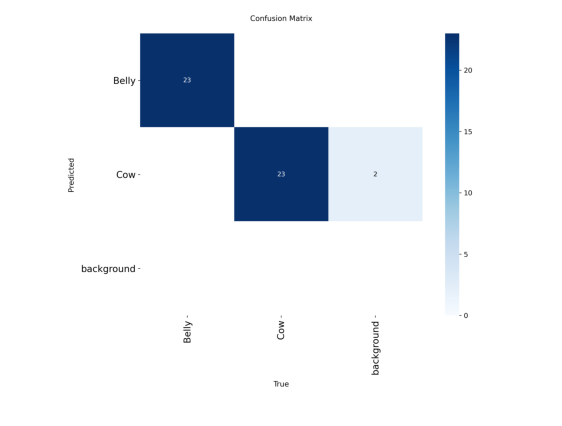

In [6]:
import matplotlib.pyplot as plt
import cv2

img = cv2.imread(
"/content/drive/MyDrive/RISET/YOLO_Training/YOLO11s_Cow_Belly/confusion_matrix.png"
)

img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(7,7))
plt.imshow(img)
plt.axis("off")
plt.show()

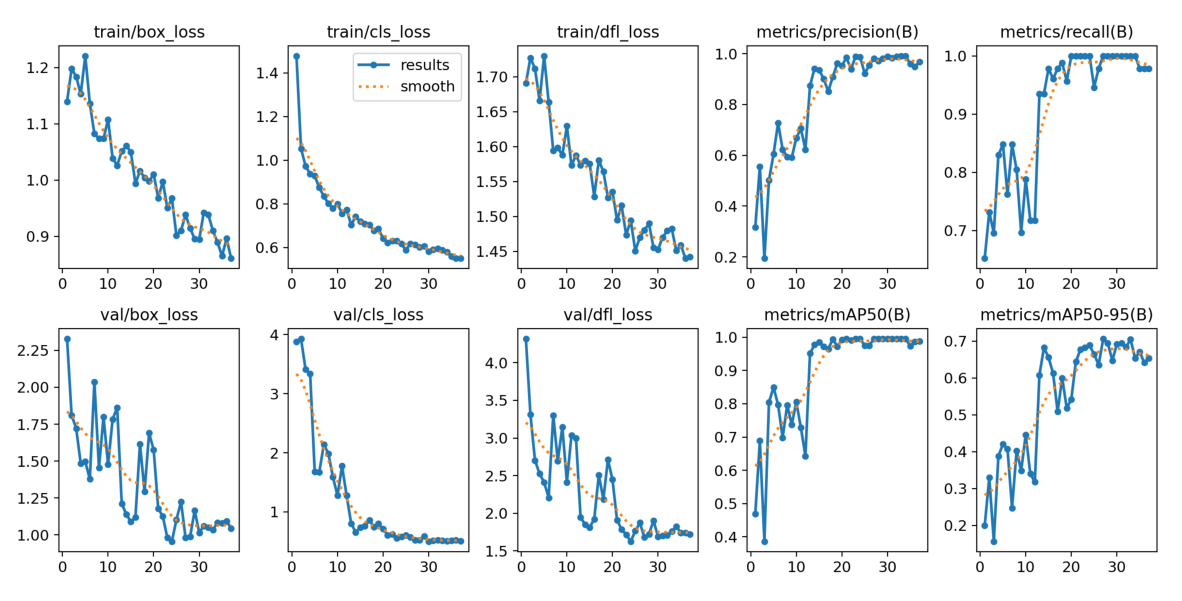

In [7]:
img = cv2.imread(
"/content/drive/MyDrive/RISET/YOLO_Training/YOLO11s_Cow_Belly/results.png"
)

img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(15,8))
plt.imshow(img)
plt.axis("off")
plt.show()

In [22]:
best_model = YOLO(
    "/content/drive/MyDrive/RISET/YOLO_Training/YOLO11s_Cow_Belly/weights/best.pt"
)

results=best_model.predict(
    source="/content/drive/MyDrive/RISET/Dataset_YOLO/test/images",
    conf=0.25,
    iou=0.5,
    save=False,
    verbose=False
)

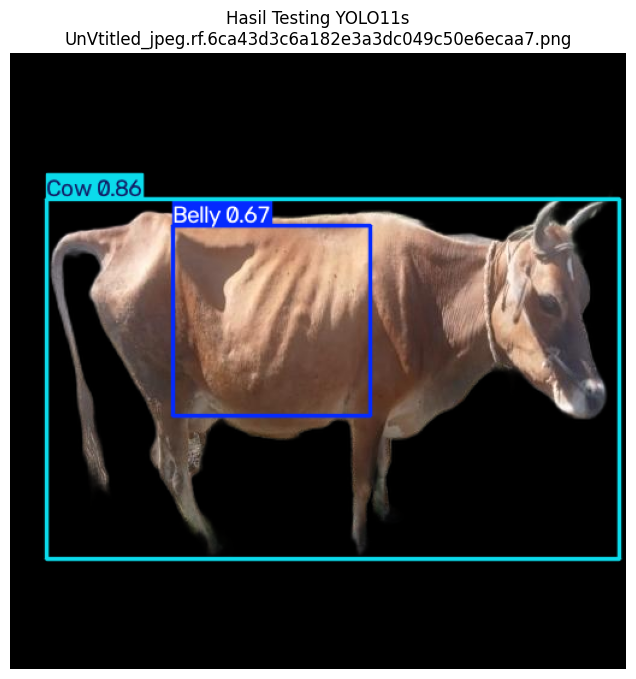

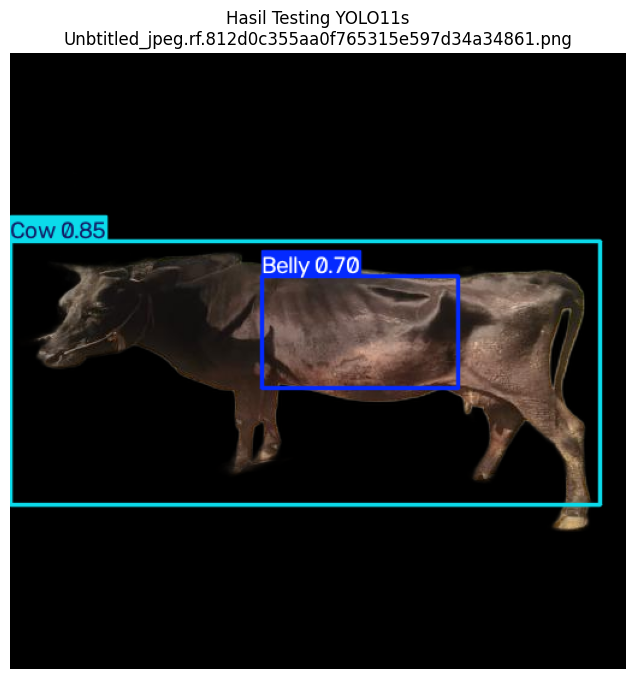

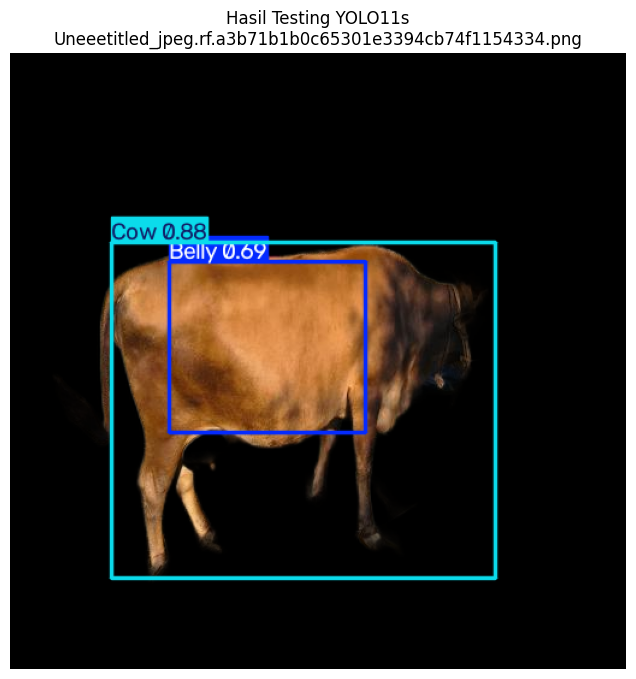

In [16]:
for result in results[:3]:
    img = result.orig_img.copy()
    plotted_img = result.plot()

    # BGR → RGB
    plotted_img = cv2.cvtColor(
        plotted_img,
        cv2.COLOR_BGR2RGB
    )

    # Nama gambar
    image_name = os.path.basename(
        result.path
    )

    plt.figure(figsize=(8, 8))
    plt.imshow(plotted_img)
    plt.title(
        f"Hasil Testing YOLO11s\n{image_name}"
    )
    plt.axis("off")
    plt.show()

In [23]:
test_metrics = best_model.val(
    data="/content/drive/MyDrive/RISET/Dataset_YOLO/data.yaml",
    split="test",
    imgsz=640,
    batch=8,
    conf=0.25,
    iou=0.5,
    plots=True,
    project="/content/drive/MyDrive/RISET/YOLO_Test_Evaluation",
    name="YOLO11s_Cow_Belly_Test",
    exist_ok=True
)

Ultralytics 8.4.117 🚀 Python-3.12.13 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
val: Fast image access ✅ (ping: 1.4±1.0 ms, read: 56.5±30.8 MB/s, size: 128.9 KB)
val: Scanning /content/drive/MyDrive/RISET/Dataset_YOLO/test/labels... 23 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 23/23 66.4it/s 0.3s
val: New cache created: /content/drive/MyDrive/RISET/Dataset_YOLO/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 7.3s/it 22.0s
                   all         23         46          1          1      0.995      0.688
                 Belly         23         23          1          1      0.995      0.515
                   Cow         23         23          1          1      0.995      0.862
Speed: 21.2ms preprocess, 884.3ms inference, 0.0ms loss, 0.6ms postprocess per image
Results saved to /content/drive/MyDrive/RISET/YOLO_Test_Evaluation/YOLO11s_Cow_Belly_Test


In [26]:
print("======================================")
print("HASIL EVALUASI DATA TEST")
print("======================================")

print(f"Precision : {test_metrics.box.mp:.4f}")
print(f"Recall    : {test_metrics.box.mr:.4f}")
print(f"mAP@50    : {test_metrics.box.map50:.4f}")
print(f"mAP@50-95 : {test_metrics.box.map:.4f}")

print("======================================")

HASIL EVALUASI DATA TEST
Precision : 1.0000
Recall    : 1.0000
mAP@50    : 0.9950
mAP@50-95 : 0.6883


In [27]:
from ultralytics import YOLO

# =====================================================
# LOAD BEST MODEL
# =====================================================

best_model = YOLO(
    "/content/drive/MyDrive/RISET/YOLO_Training/"
    "YOLO11s_Cow_Belly/weights/best.pt"
)

# =====================================================
# EVALUASI TEST
# =====================================================

test_metrics = best_model.val(
    data="/content/drive/MyDrive/RISET/Dataset_YOLO/data.yaml",
    split="test",
    imgsz=640,
    batch=8,
    conf=0.25,
    iou=0.5,
    plots=True
)

# =====================================================
# HASIL EVALUASI
# =====================================================

print("======================================")
print("HASIL EVALUASI DATA TEST")
print("======================================")

print(f"Precision  : {test_metrics.box.mp:.4f}")
print(f"Recall     : {test_metrics.box.mr:.4f}")
print(f"mAP@50     : {test_metrics.box.map50:.4f}")
print(f"mAP@50-95  : {test_metrics.box.map:.4f}")

print("======================================")

Ultralytics 8.4.117 🚀 Python-3.12.13 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11s summary (fused): 101 layers, 9,413,574 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 1.3±0.9 ms, read: 63.1±20.6 MB/s, size: 164.6 KB)
val: Scanning /content/drive/MyDrive/RISET/Dataset_YOLO/test/labels.cache... 23 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 23/23 4.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 5.9s/it 17.6s
                   all         23         46          1          1      0.995      0.688
                 Belly         23         23          1          1      0.995      0.515
                   Cow         23         23          1          1      0.995      0.862
Speed: 2.6ms preprocess, 709.1ms inference, 0.0ms loss, 0.7ms postprocess per image
Results saved to /content/runs/detect/val-2
HASIL EVALUASI DATA TEST
Precision  : 1.0000
Recall     : 1.0000
mAP@50     

In [17]:
def draw_measurement_yolo(img,image_name, x1, y1, x2, y2, class_name, color):

    # ukuran
    length = x2 - x1
    width = y2 - y1
    diagonal = int(np.sqrt(length**2 + width**2))
    area = length * width

    font = cv2.FONT_HERSHEY_SIMPLEX
    font_scale = 0.45
    thickness = 1

    # SIMPAN KE LIST
    measurement_data.append({
        "Image": image_name,
        "Class": class_name,
        "Width (px)": length,
        "Height (px)": width,
        "Diagonal (px)": diagonal,
        "Area (px²)": area
    })
    # Bounding Box
    cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)

    # -----------------------
    # Fungsi tulisan
    # -----------------------
    def draw_text(text, x, y, txt_color=(255,255,255)):

        (tw, th), _ = cv2.getTextSize(
            text,
            font,
            font_scale,
            thickness
        )

        cv2.rectangle(
            img,
            (x-2, y-th-3),
            (x+tw+2, y+3),
            (0,0,0),
            -1
        )

        cv2.putText(
            img,
            text,
            (x,y),
            font,
            font_scale,
            txt_color,
            thickness,
            cv2.LINE_AA
        )

    # Nama
    draw_text(class_name, x1+5, y1+16, color)

    # Garis horizontal
    cv2.line(img, (x1,y1), (x2,y1), color, 2)

    # Garis vertikal
    cv2.line(img, (x1,y1), (x1,y2), color, 2)

    # Width
    txt = f"W:{length}px" if class_name=="Cow" else f"BW:{length}px"

    (tw,_),_=cv2.getTextSize(
        txt,
        font,
        font_scale,
        thickness
    )

    draw_text(
        txt,
        int((x1+x2)/2-tw/2),
        y1+16
    )

    # Height
    txt = f"H:{width}px" if class_name=="Cow" else f"BH:{width}px"

    draw_text(
        txt,
        x1+5,
        int((y1+y2)/2)
    )

    # Diagonal
    if class_name=="Cow":

        cv2.line(
            img,
            (x1,y1),
            (x2,y2),
            (255,255,0),
            2
        )

        txt=f"D:{diagonal}px"

        draw_text(
            txt,
            int((x1+x2)/2-30),
            int((y1+y2)/2),
            (255,255,0)
        )

    # Area
    txt = f"A:{area:,} px²" if class_name=="Cow" else f"BA:{area:,} px²"

    draw_text(
        txt,
        x1+5,
        y2-6,
        (255,0,255)
    )



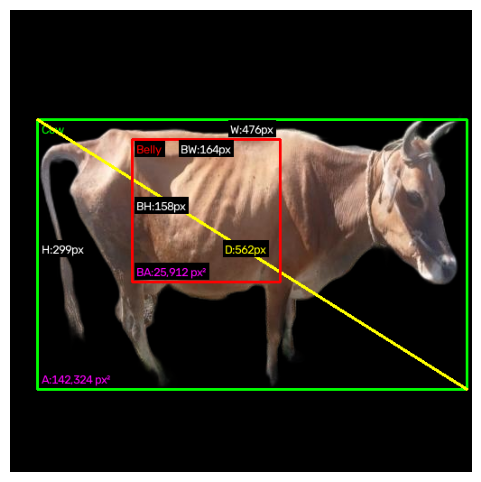

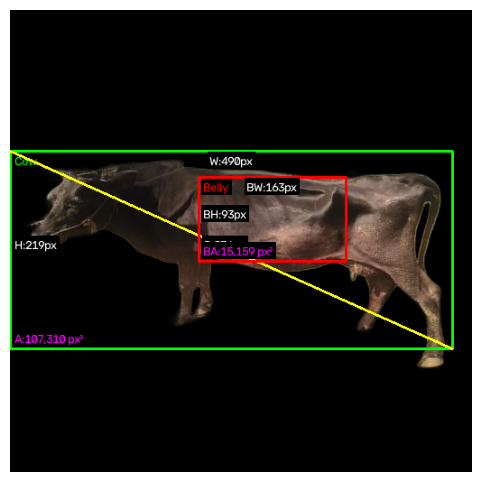

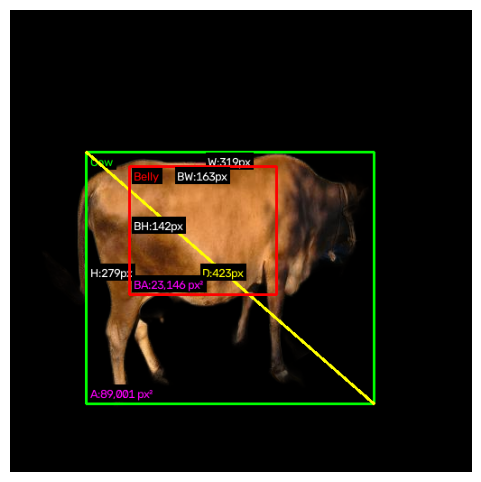

In [20]:
import numpy as np

image_name = os.path.basename(results[0].path)
measurement_data = []

for result in results[:3]:

    img = result.orig_img.copy()
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    for box in result.boxes:

        cls = int(box.cls.item())

        x1, y1, x2, y2 = map(
            int,
            box.xyxy[0].cpu().numpy()
        )

        if cls == 1:
            draw_measurement_yolo(
                img,
                image_name,
                x1, y1, x2, y2,
                "Cow",
                (0,255,0)
            )

        else:
            draw_measurement_yolo(
                img,
                image_name,
                x1, y1, x2, y2,
                "Belly",
                (255,0,0)
            )

    plt.figure(figsize=(6,6))
    plt.imshow(img)
    plt.axis("off")
    plt.show()

In [21]:
import pandas as pd

measurement_data = []

for result in results:

    img = result.orig_img.copy()

    image_name = os.path.basename(result.path)

    for box in result.boxes:

        cls = int(box.cls.item())

        x1, y1, x2, y2 = map(int, box.xyxy[0].cpu().numpy())

        width = x2 - x1
        height = y2 - y1
        diagonal = np.sqrt(width**2 + height**2)
        area = width * height

        label = "Cow" if cls == 1 else "Belly"

        measurement_data.append({
            "Image": image_name,
            "Class": label,
            "Width": width,
            "Height": height,
            "Diagonal": diagonal,
            "Area": area
        })

df = pd.DataFrame(measurement_data)
csv_path = df.to_csv("/content/drive/MyDrive/RISET/morphology_measurement.csv", index=False)

print("CSV berhasil disimpan")
print(csv_path)

print(df.head())
print("Jumlah data:", len(df))

CSV berhasil disimpan
None
                                               Image  Class  Width  Height  \
0  UnVtitled_jpeg.rf.6ca43d3c6a182e3a3dc049c50e6e...    Cow    476     299   
1  UnVtitled_jpeg.rf.6ca43d3c6a182e3a3dc049c50e6e...  Belly    164     158   
2  Unbtitled_jpeg.rf.812d0c355aa0f765315e597d34a3...    Cow    490     219   
3  Unbtitled_jpeg.rf.812d0c355aa0f765315e597d34a3...  Belly    163      93   
4  Uneeetitled_jpeg.rf.a3b71b1b0c65301e3394cb74f1...    Cow    319     279   

     Diagonal    Area  
0  562.118315  142324  
1  227.727908   25912  
2  536.713145  107310  
3  187.664594   15159  
4  423.794762   89001  
Jumlah data: 46
